In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# The training dataset comprises 343746 rows and 21 columns
taxi = pd.read_csv("https://datasciencebocconi.github.io/Data/taxi_train.csv")

# The training dataset comprises 147546 rows and 19 columns (the label `response` is not available)
taxi_pred = pd.read_csv("https://datasciencebocconi.github.io/Data/taxi_test.csv")

In [4]:
# Let's have a look at the training dataset
taxi

,weight,response,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,...,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,fare_amount,pair
0,1,1.75,18,5,19,132,4,520,1,MN15,...,MN19,-73.983009,40.766602,-73.967972,40.760677,1,1,0.90,7.0,MN15-MN19
1,1,2.95,18,5,19,127,6,824,1,MN21,...,MN24,-73.989510,40.734470,-73.997185,40.717976,1,1,1.40,10.0,MN21-MN24
2,1,2.46,7,5,19,132,4,1016,1,MN25,...,MN27,-74.012741,40.702229,-73.998878,40.713711,2,1,1.14,11.5,MN25-MN27
3,1,1.66,11,5,20,134,6,550,1,MN99,...,MN20,-73.970909,40.767231,-73.979507,40.752331,2,1,1.28,7.5,MN99-MN20
4,1,1.75,20,5,19,128,7,501,1,MN20,...,MN22,-73.973869,40.747925,-73.986618,40.730328,1,1,1.40,7.5,MN20-MN22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343741,1,2.00,20,5,21,145,3,740,1,MN12,...,MN36,-73.978676,40.783512,-73.938370,40.850533,2,1,5.84,18.5,MN12-MN36
343742,1,1.00,23,5,21,141,6,193,1,MN14,...,MN12,-73.982048,40.775452,-73.976860,40.783520,2,6,0.70,4.5,MN14-MN12
343743,1,2.35,19,5,19,132,4,764,1,MN20,...,MN22,-73.974472,40.747253,-73.983070,40.726955,1,1,1.70,10.0,MN20-MN22
343744,1,2.65,21,5,20,140,5,955,1,MN13,...,MN27,-73.993607,40.745293,-73.987350,40.722256,1,1,2.20,12.0,MN13-MN27


In [5]:
taxi.shape

(343746, 21)

In [6]:
taxi.columns

Index(['weight', 'response', 'pickup_hour', 'pickup_month', 'pickup_week',
       'pickup_doy', 'pickup_wday', 'length_time', 'pickup_BoroCode',
       'pickup_NTACode', 'dropoff_BoroCode', 'dropoff_NTACode',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'vendor_id', 'passenger_count', 'trip_distance',
       'fare_amount', 'pair'],
      dtype='object')

+ `response`: The response variable, i.e. the tip amount in US dollars
+ `weight`: constant variable that can be removed because the evaluation score is not weighted
+ `pickup_hour`: Hour of the pick-up 
+ `pickup_month`: Month of the pick-up (always May)
+ `pickup_week`: Week of the pick-up
+ `pickup_doy`: Day of the year of the pick-up (from 1 to 365)
+ `pickup_wday`: Day of the week of the pick-up (from 1 to 7)
+ `length_time`: Duration of the ride (in seconds)
+ `pickup_BoroCode`: Macro-area of the pick-up
+ `pickup_NTACode`: Micro-area of the pick-up (Neighborhood Tabulation Areas)
+ `dropoff_BoroCode`: Macro-area of the drop-off
+ `dropoff_NTACode`: Micro-area of the drop-off (Neighborhood Tabulation Areas)
+ `pickup_longitude`: Longitude of the pick-up
+ `pickup_latitude`: Latitude of the pick-up
+ `dropoff_longitude`: Longitude of the drop-off
+ `dropoff_latitude`: Latitude of the drop-off
+ `vendor_id`: The TPEP provider that provided the record
+ `passenger_count`: The number of passengers in the vehicle. This is a driver-entered value.
+ `trip_distance`: The elapsed trip distance in miles reported by the taximeter
+ `fare_amount`: The time-and-distance fare calculated by the meter
+ `pair`: Combination of the variables pickup_NTACode and dropoff_NTACode

In [7]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343746 entries, 0 to 343745
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   weight             343746 non-null  int64  
 1   response           343746 non-null  float64
 2   pickup_hour        343746 non-null  int64  
 3   pickup_month       343746 non-null  int64  
 4   pickup_week        343746 non-null  int64  
 5   pickup_doy         343746 non-null  int64  
 6   pickup_wday        343746 non-null  int64  
 7   length_time        343746 non-null  int64  
 8   pickup_BoroCode    343746 non-null  int64  
 9   pickup_NTACode     343746 non-null  object 
 10  dropoff_BoroCode   343746 non-null  int64  
 11  dropoff_NTACode    343746 non-null  object 
 12  pickup_longitude   343746 non-null  float64
 13  pickup_latitude    343746 non-null  float64
 14  dropoff_longitude  343746 non-null  float64
 15  dropoff_latitude   343746 non-null  float64
 16  ve

In [8]:
taxi.rename(columns={'response': 'tip_amount'}, inplace=True)


In [9]:
taxi.insert(2, "tip_percentage", taxi["tip_amount"] / taxi["fare_amount"] * 100)

In [10]:
taxi.drop(columns = ['weight'])

,tip_amount,tip_percentage,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,...,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,fare_amount,pair
0,1.75,25.000000,18,5,19,132,4,520,1,MN15,...,MN19,-73.983009,40.766602,-73.967972,40.760677,1,1,0.90,7.0,MN15-MN19
1,2.95,29.500000,18,5,19,127,6,824,1,MN21,...,MN24,-73.989510,40.734470,-73.997185,40.717976,1,1,1.40,10.0,MN21-MN24
2,2.46,21.391304,7,5,19,132,4,1016,1,MN25,...,MN27,-74.012741,40.702229,-73.998878,40.713711,2,1,1.14,11.5,MN25-MN27
3,1.66,22.133333,11,5,20,134,6,550,1,MN99,...,MN20,-73.970909,40.767231,-73.979507,40.752331,2,1,1.28,7.5,MN99-MN20
4,1.75,23.333333,20,5,19,128,7,501,1,MN20,...,MN22,-73.973869,40.747925,-73.986618,40.730328,1,1,1.40,7.5,MN20-MN22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343741,2.00,10.810811,20,5,21,145,3,740,1,MN12,...,MN36,-73.978676,40.783512,-73.938370,40.850533,2,1,5.84,18.5,MN12-MN36
343742,1.00,22.222222,23,5,21,141,6,193,1,MN14,...,MN12,-73.982048,40.775452,-73.976860,40.783520,2,6,0.70,4.5,MN14-MN12
343743,2.35,23.500000,19,5,19,132,4,764,1,MN20,...,MN22,-73.974472,40.747253,-73.983070,40.726955,1,1,1.70,10.0,MN20-MN22
343744,2.65,22.083333,21,5,20,140,5,955,1,MN13,...,MN27,-73.993607,40.745293,-73.987350,40.722256,1,1,2.20,12.0,MN13-MN27


In [11]:
taxi["tip_amount"].mean()

2.8349105153223597

In [12]:
taxi["tip_percentage"].mean()

22.04414936945497

<Axes: xlabel='tip_amount'>

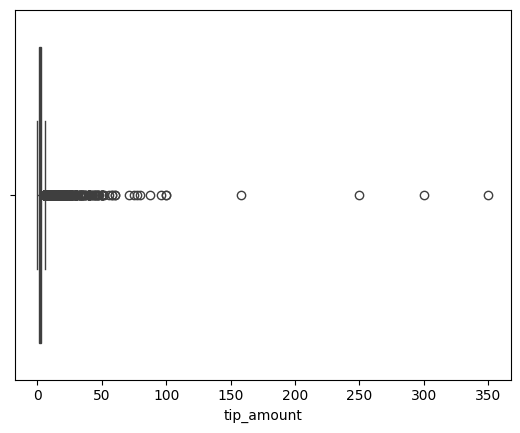

In [13]:
sns.boxplot(data=taxi, x="tip_amount") 


<Axes: xlabel='tip_amount'>

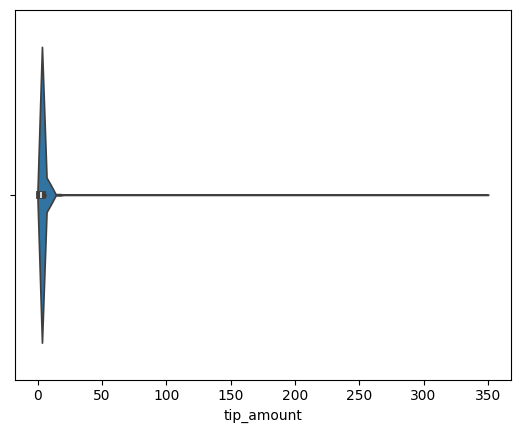

In [14]:
sns.violinplot(data=taxi, x="tip_amount") 

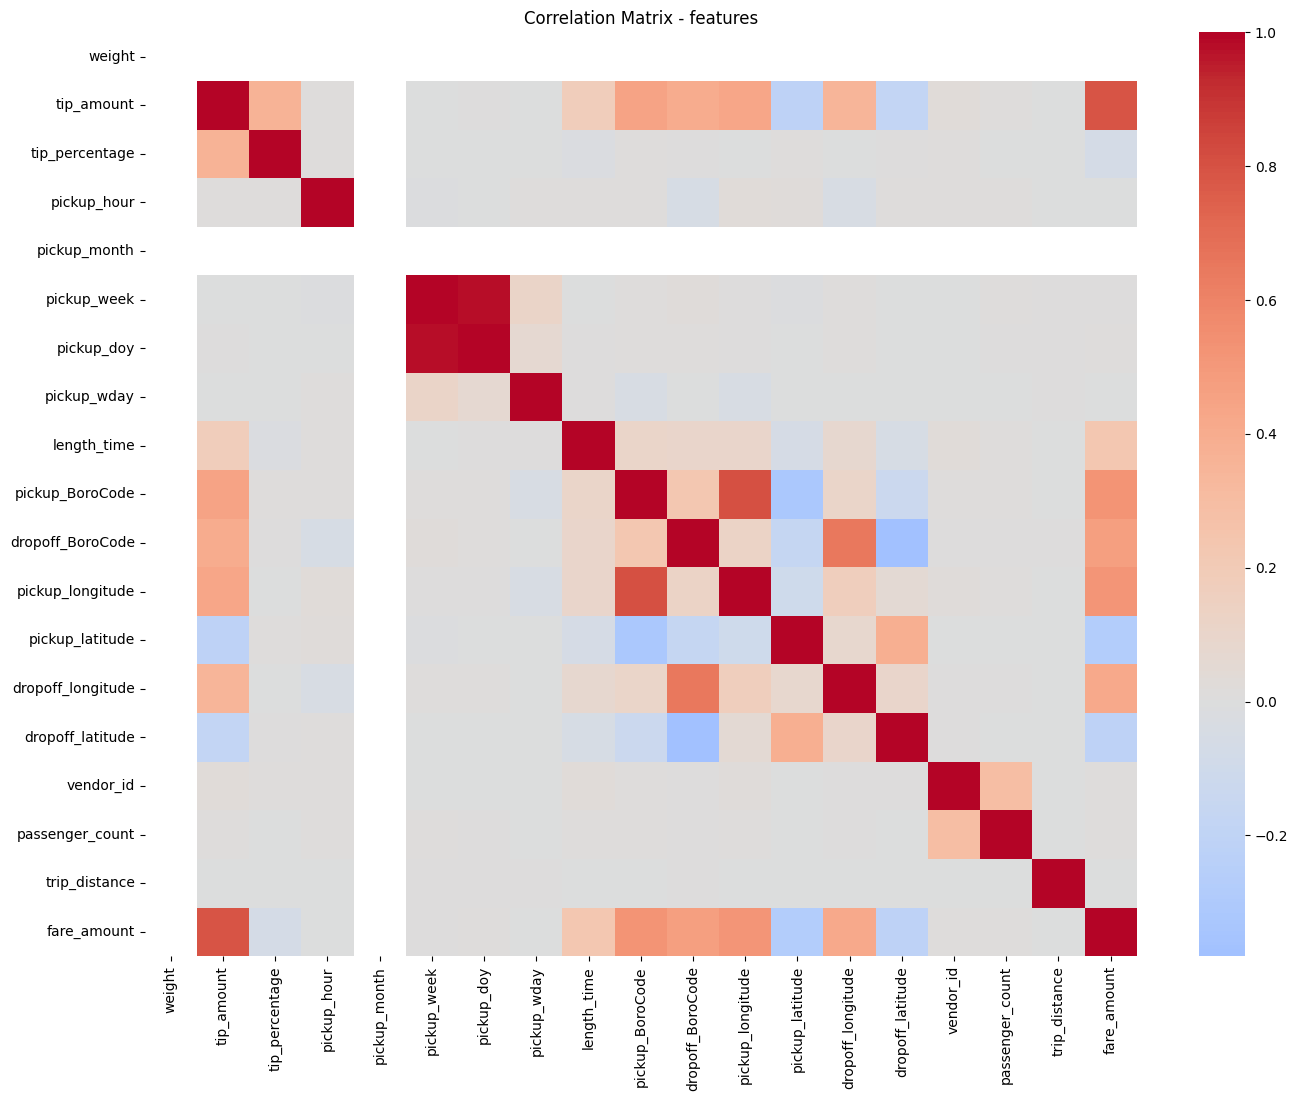

In [16]:
# Select only numeric columns
numeric_cols = taxi.select_dtypes(include=[np.number])

# Compute the correlation matrix for numeric features
corr_matrix_f = numeric_cols.corr()

# Plot a heatmap of the correlation matrix
fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(corr_matrix_f, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)

midpoint = (corr_matrix_f.values.max() - corr_matrix_f.values.min()) / 2 + corr_matrix_f.values.min()
plt.title("Correlation Matrix - features")
plt.show()


we can see a relatively high correlation of tip_amount with fare_amount, manhattan_distance, trip_distance, and lenght_time